# Pilar 3 — Integração com outros modais (tratamento inicial)

**Fontes**
- EPTC / ObservaMOB (Dados Espaciais): ciclovias implantadas, rede PDCI, paradas, corredores, paraciclos, BikePoa e bairros.
https://drive.procempa.com.br/s/LJp8MNCFmZKdPpD 


In [1]:
from pathlib import Path

import folium
import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd

# Raiz do projeto (funciona rodando o notebook de dentro da pasta notebooks/)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "1_raw" / "pilar3"
DONE = ROOT / "data" / "3_done"
DONE.mkdir(parents=True, exist_ok=True)

CRS_GEO = 4326  # latitude/longitude: para guardar e fazer mapas
CRS_M = 31982   # SIRGAS 2000 / UTM 22S, em metros: para distâncias e comprimentos

# Carregar os dados brutos
A função abaixo procura o arquivo pelo começo do nome (as datas no nome mudam quando a EPTC atualiza)
e pega o mais recente.

In [2]:
def carregar(prefixo):
    """Acha o .geojson mais recente que começa com `prefixo` em data/1_raw/pilar3."""
    achados = sorted(RAW.glob(f"{prefixo}*.geojson"))
    if not achados:
        print(f"[AVISO] não encontrei '{prefixo}*' em {RAW}")
        return None
    g = gpd.read_file(achados[-1])
    print(f"{achados[-1].name}: {len(g)} linhas")
    return g


brutos = {
    "bairros": carregar("Bairros"),
    "ciclovias": carregar("CicloviasImplantadas"),
    "rede_pdci": carregar("RedeCicloviariaPDCI"),
    "paradas": carregar("Paradas"),
    "corredores": carregar("CorredoresFaixasExclusivas"),
    "paraciclos": carregar("ParaciclosImplantados"),
    "bikepoa": carregar("BikePoa"),
    "osm_bicicletarios": carregar("osm_bicicletarios"),
    "osm_ciclovias": carregar("osm_ciclovias"),
}

Bairros_LC12112_16.geojson: 128 linhas
CicloviasImplantadas_20261112.geojson: 97 linhas
RedeCicloviariaPDCI_20251202.geojson: 4144 linhas
Paradas_20261112.geojson: 5913 linhas
CorredoresFaixasExclusivas_20260909.geojson: 47 linhas
ParaciclosImplantados_20261112.geojson: 47 linhas
BikePoa_20261112.geojson: 90 linhas
[AVISO] não encontrei 'osm_bicicletarios*' em c:\Users\ResTIC55\Documents\eld_dataset\data\1_raw\pilar3
[AVISO] não encontrei 'osm_ciclovias*' em c:\Users\ResTIC55\Documents\eld_dataset\data\1_raw\pilar3


# Olhar os dados antes de mexer
Para cada camada: quantas linhas, se há geometria vazia e quais colunas têm muitos valores vazios.

In [4]:
def resumo(g, nome):
    if g is None:
        return
    vazias = int((g.geometry.isna() | g.geometry.is_empty).sum())
    print(f"=== {nome} ===")
    print(f"linhas: {len(g)} | geometrias vazias: {vazias} | tipos: {list(g.geom_type.dropna().unique())}")
    nulos = (g.drop(columns="geometry").isna().mean() * 100).round(0)
    nulos = nulos[nulos > 0].sort_values(ascending=False)
    if len(nulos):
        print("colunas com valores vazios (%):", nulos.head(8).to_dict())
    print()


for nome, g in brutos.items():
    resumo(g, nome)

=== bairros ===
linhas: 128 | geometrias vazias: 0 | tipos: ['Polygon']
colunas com valores vazios (%): {'EDITOR': 100.0}

=== ciclovias ===
linhas: 97 | geometrias vazias: 0 | tipos: ['LineString', 'MultiLineString']

=== rede_pdci ===
linhas: 4144 | geometrias vazias: 0 | tipos: ['LineString', 'MultiLineString']
colunas com valores vazios (%): {'PROJECAO': 84.0, 'TIPO': 83.0, 'RECURSO': 76.0, 'DUPLICACAO': 58.0, 'ROTULO': 5.0, 'REGIAO': 4.0, 'SITUACAO': 2.0, 'HIERARQUIA': 2.0}

=== paradas ===
linhas: 5913 | geometrias vazias: 0 | tipos: ['Point']
colunas com valores vazios (%): {'COMPLEMENT': 100.0, 'DATA_FINAL': 100.0, 'CONSRCIO': 100.0, 'M2_EXT': 99.0, 'POTENCIAL_': 99.0, 'ESPELHADA': 98.0, 'ESTAO': 97.0, 'TERMINAL': 96.0}

=== corredores ===
linhas: 47 | geometrias vazias: 0 | tipos: ['MultiLineString', 'LineString']
colunas com valores vazios (%): {'DATA_RE': 98.0, 'HORARIO2': 64.0}

=== paraciclos ===
linhas: 47 | geometrias vazias: 0 | tipos: ['Point']
colunas com valores vazi

# Ficar só com as colunas úteis


In [5]:
COLUNAS = {
    "bairros": {"CODIGO": "codigo", "NOME": "bairro"},
    "ciclovias": {"NOME": "nome", "SITUACAO": "situacao", "TIPO": "tipo",
                  "TRECHO": "trecho", "DATA": "data"},
    "rede_pdci": {"NOME": "nome", "REGIAO": "regiao", "LARGURA": "largura",
                  "HIERARQUIA": "hierarquia", "CICLOVIA": "ciclovia",
                  "SITUACAO": "situacao", "TIPO": "tipo"},
    "paradas": {"PCODIGO": "id_parada", "BAIRRO": "bairro", "PLOGR": "logradouro",
                "LINHAS": "linhas", "TERMINAL": "terminal", "ESTAO": "estacao",
                "DATA_FINAL": "data_final"},
    "corredores": {"NOME_CO": "corredor", "NMIDELO": "logradouro",
                   "TRANSPO": "transporte", "SITUACA": "situacao", "ANO": "ano"},
    "paraciclos": {"Name": "nome", "Quantidade": "quantidade", "Local": "local"},
    "bikepoa": {"NUMERO_EST": "id_estacao", "NOME": "nome", "BAIRRO": "bairro",
                "STATUS_EST": "status", "VAGAS_DOCK": "vagas"},
    "osm_bicicletarios": {"name": "nome", "capacity": "quantidade"},
    "osm_ciclovias": {"name": "nome"},
}


def selecionar(g, mapa, nome):
    if g is None:
        return None
    faltando = [c for c in mapa if c not in g.columns]
    if faltando:
        print(f"{nome}: colunas não encontradas (ignoradas): {faltando}")
    ficam = {c: novo for c, novo in mapa.items() if c in g.columns}
    return g[list(ficam) + ["geometry"]].rename(columns=ficam).copy()


camadas = {nome: selecionar(g, COLUNAS[nome], nome) for nome, g in brutos.items()}

# Limpeza no geral
Para cada camada:
1. tira linhas **sem geometria**;
2. tira **espaços sobrando** nos textos e troca texto vazio (ou "nan") por valor vazio;
3. tira linhas **repetidas**;
4. tira o que cair **fora de Porto Alegre** (usando o limite dos bairros, com 200 m de folga).

Se sobrar menos da metade dos dados, o script avisa: pode ser problema de projeção.

In [6]:
def unir(geoseries):
    return geoseries.union_all() if hasattr(geoseries, "union_all") else geoseries.unary_union


bairros_m = camadas["bairros"].to_crs(CRS_M)
limite_poa = gpd.GeoSeries(
    [unir(bairros_m.geometry.make_valid()).buffer(200)], crs=CRS_M
).to_crs(CRS_GEO).iloc[0]


def vazio_para_none(v):
    if isinstance(v, str):
        v = v.strip()
        return None if v.lower() in ("", "nan", "none") else v
    return v


def limpar_texto(g):
    for c in g.columns:
        eh_texto = g[c].dtype == object or pd.api.types.is_string_dtype(g[c])
        if c != "geometry" and eh_texto:
            g[c] = g[c].astype(object).apply(vazio_para_none)


def limpar(g, nome):
    if g is None:
        return None
    n0 = len(g)
    g = g[~(g.geometry.isna() | g.geometry.is_empty)].copy().to_crs(CRS_GEO)
    limpar_texto(g)

    chave = g.drop(columns="geometry").astype(str)
    chave["_geom"] = g.geometry.to_wkb()
    g = g[~chave.duplicated()].copy()
    n1 = len(g)

    g = g[g.intersects(limite_poa)].reset_index(drop=True)
    print(f"{nome}: {n0} -> {len(g)} (vazias/repetidas: {n0 - n1}, fora de POA: {n1 - len(g)})")
    if n1 and len(g) < 0.5 * n1:
        print(f"   [ATENÇÃO] {nome}: mais da metade ficou fora de Porto Alegre. Confira a projeção.")
    return g


limpas = {nome: limpar(g, nome) for nome, g in camadas.items() if nome != "bairros"}
limpas["bairros"] = camadas["bairros"].to_crs(CRS_GEO)

ciclovias: 97 -> 97 (vazias/repetidas: 0, fora de POA: 0)
rede_pdci: 4144 -> 4122 (vazias/repetidas: 10, fora de POA: 12)
paradas: 5913 -> 5871 (vazias/repetidas: 3, fora de POA: 39)
corredores: 47 -> 47 (vazias/repetidas: 0, fora de POA: 0)
paraciclos: 47 -> 47 (vazias/repetidas: 0, fora de POA: 0)
bikepoa: 90 -> 90 (vazias/repetidas: 0, fora de POA: 0)


# Bicicletários: juntar EPTC + OSM


In [7]:
def para_pontos(g):
    gm = g.to_crs(CRS_M)
    gm["geometry"] = gm.geometry.centroid
    return gm.to_crs(CRS_GEO)


def preparar_bici(g, fonte):
    if g is None or len(g) == 0:
        return None
    p = para_pontos(g)
    p["fonte"] = fonte
    if "quantidade" not in p.columns:
        p["quantidade"] = None
    p["quantidade"] = pd.to_numeric(p["quantidade"], errors="coerce")
    if "nome" not in p.columns:
        p["nome"] = None
    return p[["nome", "quantidade", "fonte", "geometry"]]


eptc_b = preparar_bici(limpas.get("paraciclos"), "EPTC")
osm_b = preparar_bici(limpas.get("osm_bicicletarios"), "OSM")

if eptc_b is not None and osm_b is not None:
    perto = gpd.sjoin_nearest(
        osm_b.to_crs(CRS_M), eptc_b.to_crs(CRS_M)[["geometry"]], max_distance=15
    )
    repetidos = perto.index.unique()
    print(f"OSM: {len(osm_b)} pontos, {len(repetidos)} repetem os da EPTC e serão removidos")
    osm_b = osm_b.drop(index=repetidos)

partes = [p for p in (eptc_b, osm_b) if p is not None]
bicicletarios = gpd.GeoDataFrame(pd.concat(partes, ignore_index=True), geometry="geometry", crs=CRS_GEO)
print(bicicletarios["fonte"].value_counts().to_dict())

{'EPTC': 47}


# Ciclovias: comparar as fontes
Comparar o que a EPTC (oficial) e o OSM têm mostra **quanto o OSM está incompleto**.
O oficial deve ficar perto dos 95 km informados pela prefeitura.
A rede PDCI inclui trechos **previstos**, por isso é bem maior: a coluna `situacao` separa o que existe do que é planejado.

In [8]:
def km(g):
    return round(g.to_crs(CRS_M).length.sum() / 1000, 1) if g is not None else None


print("Ciclovias EPTC implantadas (km):", km(limpas.get("ciclovias")))
print("Ciclovias OSM (km):", km(limpas.get("osm_ciclovias")))
print("Rede PDCI, existente + prevista (km):", km(limpas.get("rede_pdci")))

if limpas.get("rede_pdci") is not None:
    print("\nSituação dos trechos da rede PDCI:")
    print(limpas["rede_pdci"]["situacao"].value_counts(dropna=False))

# comprimento de cada trecho em metros, calculado a partir do desenho
for nome in ("ciclovias", "rede_pdci", "corredores", "osm_ciclovias"):
    g = limpas.get(nome)
    if g is not None:
        g["comprimento_m"] = g.to_crs(CRS_M).length.round(1)

Ciclovias EPTC implantadas (km): 95.2
Ciclovias OSM (km): None
Rede PDCI, existente + prevista (km): 533.7

Situação dos trechos da rede PDCI:
situacao
PLANO                   2712
CONCLUIDO                727
PROJETO                  484
NaN                       90
Ciclorrota Projeto        79
OBRA                      21
COMPARTILHADA              5
REMOVIDO                   2
CONCLUIDO_NoExtensao       2
Name: count, dtype: int64


# Conferir as paradas
Algumas paradas podem ter uma data final preenchida. Se forem muitas, talvez estejam **desativadas**.
Vale confirmar o significado dessa coluna com a EPTC antes de decidir se filtramos.

In [9]:
paradas = limpas.get("paradas")
if paradas is not None:
    print("paradas com data_final preenchida:", int(paradas["data_final"].notna().sum()), "de", len(paradas))
    print("paradas em terminal:", int(paradas["terminal"].notna().sum()))
    print("\nExemplos da coluna 'linhas':")
    print(paradas["linhas"].dropna().head(5).tolist())

paradas com data_final preenchida: 9 de 5871
paradas em terminal: 224

Exemplos da coluna 'linhas':
['345', 'R9', '718', 'DESEMBARQUE', 'T2, T2A, T12, T12A, 613.5']


# Visualização
Primeiro um mapa estático com todas as camadas, depois as paradas por bairro.

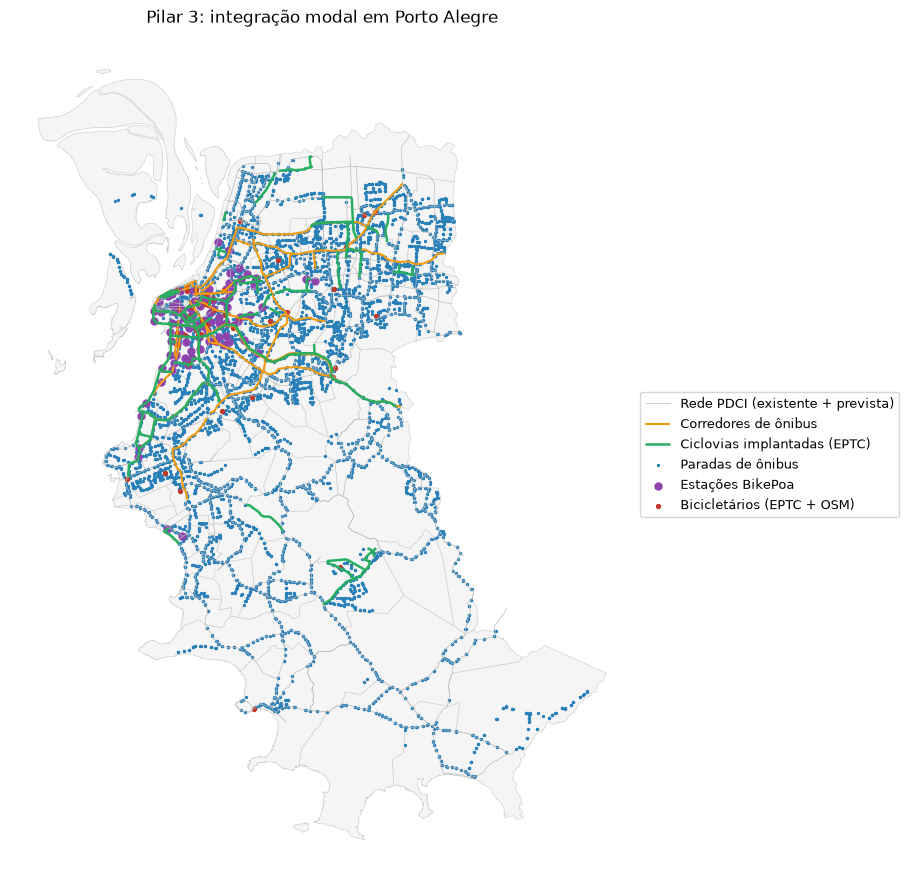

In [10]:
estilos = [
    ("rede_pdci", "Rede PDCI (existente + prevista)", dict(color="#bbbbbb", linewidth=0.5)),
    ("corredores", "Corredores de ônibus", dict(color="#f39c12", linewidth=1.5)),
    ("ciclovias", "Ciclovias implantadas (EPTC)", dict(color="#27ae60", linewidth=1.8)),
    ("paradas", "Paradas de ônibus", dict(color="#2980b9", markersize=2)),
    ("bikepoa", "Estações BikePoa", dict(color="#8e44ad", markersize=25)),
]

fig, ax = plt.subplots(figsize=(10, 11))
limpas["bairros"].plot(ax=ax, color="#f5f5f5", edgecolor="#cccccc", linewidth=0.4)
for nome, rotulo, estilo in estilos:
    g = limpas.get(nome)
    if g is not None and len(g):
        g.plot(ax=ax, label=rotulo, **estilo)
bicicletarios.plot(ax=ax, color="#c0392b", markersize=8, label="Bicicletários (EPTC + OSM)")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), fontsize=9)
ax.set_title("Pilar 3: integração modal em Porto Alegre")
ax.set_axis_off()
plt.show()

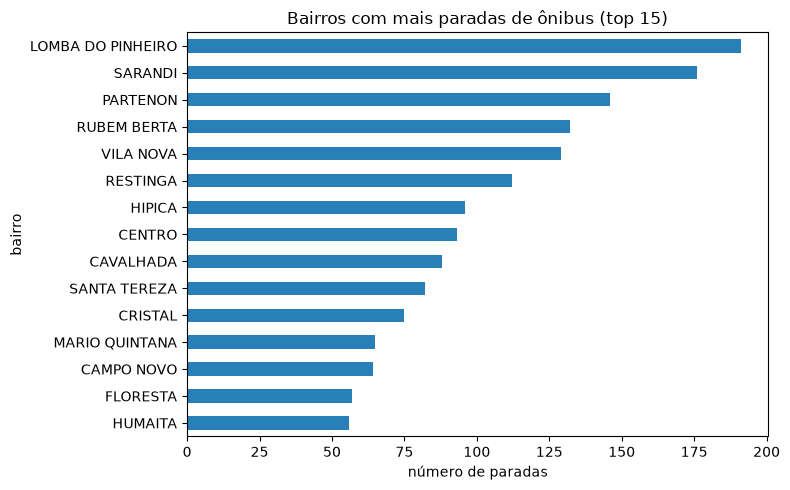

In [11]:
if paradas is not None:
    top = paradas["bairro"].value_counts().head(15).sort_values()
    top.plot.barh(figsize=(8, 5), color="#2980b9")
    plt.title("Bairros com mais paradas de ônibus (top 15)")
    plt.xlabel("número de paradas")
    plt.tight_layout()
    plt.show()

## 9. Mapa interativo (opcional)
Gera um HTML em `data/3_done/` para abrir no navegador (não vai para o GitHub, pois `data/` é ignorado).

In [12]:
m = limpas["bairros"].explore(
    color="gray", style_kwds={"fill": False, "weight": 1},
    tiles="Esri.WorldGrayCanvas", name="Bairros", tooltip=False,
)
camadas_mapa = [
    ("ciclovias", "Ciclovias implantadas", "green", {}),
    ("corredores", "Corredores de ônibus", "orange", {}),
    ("paradas", "Paradas de ônibus", "blue", dict(marker_kwds={"radius": 2})),
    ("bikepoa", "BikePoa", "purple", dict(marker_kwds={"radius": 5})),
]
for nome, rotulo, cor, extra in camadas_mapa:
    g = limpas.get(nome)
    if g is not None and len(g):
        g.explore(m=m, color=cor, name=rotulo, tooltip=False, **extra)
bicicletarios.explore(m=m, color="red", name="Bicicletários", tooltip=False,
                      marker_kwds={"radius": 3})
folium.LayerControl().add_to(m)
m.save(DONE / "mapa_pilar3.html")
print("Mapa salvo em:", DONE / "mapa_pilar3.html")

Mapa salvo em: c:\Users\ResTIC55\Documents\eld_dataset\data\3_done\mapa_pilar3.html


# Salvamento das camadas tratadas


In [13]:
finais = {
    "ciclovias_existentes": limpas.get("ciclovias"),
    "rede_pdci": limpas.get("rede_pdci"),
    "paradas_onibus": limpas.get("paradas"),
    "corredores_onibus": limpas.get("corredores"),
    "bicicletarios": bicicletarios,
    "bikepoa": limpas.get("bikepoa"),
    "ciclovias_osm": limpas.get("osm_ciclovias"),
}

for nome, g in finais.items():
    if g is None or len(g) == 0:
        print(f"{nome}: sem dados, não salvo")
        continue
    g.to_file(DONE / f"pilar3_{nome}.geojson", driver="GeoJSON")
    tab = g.drop(columns="geometry")
    if (g.geom_type == "Point").all():
        tab["lat"], tab["lon"] = g.geometry.y.round(6), g.geometry.x.round(6)
    tab.to_csv(DONE / f"pilar3_{nome}.csv", index=False)
    print(f"{nome}: {len(g)} linhas salvas")

ciclovias_existentes: 97 linhas salvas
rede_pdci: 4122 linhas salvas
paradas_onibus: 5871 linhas salvas
corredores_onibus: 47 linhas salvas
bicicletarios: 47 linhas salvas
bikepoa: 90 linhas salvas
ciclovias_osm: sem dados, não salvo
